## Problema - Laboratorio: Gestión de tareas con Heap y Cola de Prioridad

**Instrucción:** completa esta plantilla con tu diseño y desarrollo. Evita incluir soluciones generadas automáticamente.



In [1]:
# @title Ingrese datos
nombre_estudiante = "Maria Isabela Melendez Moreno" # @param {"type":"string"}
carnet = 1000109824 # @param {"type":"integer"}


## 1) Descripción del problema **[1 pts]**


Un centro de cómputo recibe tareas que deben ser procesadas por sus servidores. Cada tarea tiene un código único, un nombre y una prioridad numérica entera. Una prioridad mayor significa que la tarea debe atenderse primero.

El programa registra las tareas en el orden de entrada, construye manualmente un Max-Heap almacenado en un arreglo y permite consultar la tarea de mayor prioridad, extraerla sin perder la propiedad del heap e insertar tareas nuevas. Finalmente, aplica HeapSort manual sobre las prioridades para mostrarlas en orden ascendente.

La solución no utiliza heapq, sort() ni sorted(), y no utiliza nodos ni punteros para representar el heap. Las entradas interactivas validan los tipos permitidos y vuelven a solicitar el dato cuando hay un error.

## 2) Requerimientos **[2 pts]**

Lista requerimientos **funcionales** y **no funcionales**.



Requerimientos funcionales
- RQF01 – Registrar tareas: solicitar una cantidad entera positiva y leer para cada tarea su código, nombre y prioridad entera.
- RQF02 – Validar entradas: rechazar valores vacíos, cantidades no enteras, prioridades no enteras y códigos repetidos; mostrar el error y volver a solicitar el dato.
- RQF03 – Mostrar lista original: conservar y mostrar las prioridades en el mismo orden en que fueron ingresadas.
- RQF04 – Construir Max-Heap: implementar MAX-HEAPIFY y BUILD-MAX-HEAP manualmente usando un arreglo.
- RQF05 – Consultar máximo: mostrar la tarea ubicada en la raíz sin eliminarla.
- RQF06 – Extraer máximo: retirar y mostrar la tarea con mayor prioridad, y restaurar la propiedad del heap.
- RQF07 – Insertar tarea: registrar una nueva tarea y subirla por el heap hasta su posición correcta.
- RQF08 – Ordenar con HeapSort: ordenar las prioridades manualmente en orden ascendente, sin usar sort() ni sorted().
- RQF09 – Mostrar evidencias: imprimir la lista original, el heap construido, una representación del árbol, las operaciones de la cola de prioridad y el resultado de HeapSort.

Requerimientos no funcionales
- RQNF01 – Eficiencia: construir el heap en tiempo \(O(n)\); consultar el máximo en \(O(1)\); extraer e insertar en \(O(\log n)\); HeapSort en \(O(n\log n)\).
- RQNF02 – Mantenibilidad: organizar la solución en funciones con nombres descriptivos y responsabilidades específicas.
- RQNF03 – Robustez: validar entradas para evitar que datos incorrectos detengan la ejecución.
- RQNF04 – Restricciones de implementación: utilizar únicamente arreglos/listas de Python para el heap, sin heapq, nodos ni punteros, y programar manualmente los algoritmos solicitados.
- RQNF05 – Claridad: mostrar mensajes y resultados que permitan verificar cada punto del laboratorio.

## 3) Historias de usuario **[2 pts]**
Escribe 3–5 historias de usuario con el formato visto en clase:
Incluye criterios de aceptación.


HU01 – Registrar tareas
Como operador del centro de cómputo, quiero ingresar el código, nombre y prioridad de cada tarea, para registrar el trabajo pendiente.

Criterios de aceptación
- El sistema solicita una cantidad entera positiva de tareas.
- Cada código debe ser único y cada nombre no puede estar vacío.
- La prioridad debe ser un número entero; si el dato es inválido, se muestra un error y se solicita nuevamente.
- El sistema muestra las prioridades en su orden original.

HU02 – Consultar la tarea más prioritaria
Como operador, quiero consultar la tarea de mayor prioridad, para saber cuál debería procesarse primero.

Criterios de aceptación
- El sistema consulta la raíz del Max-Heap.
- Muestra código, nombre y prioridad.
- La consulta no elimina ni modifica la tarea.

HU03 – Procesar la tarea prioritaria
Como operador, quiero extraer la tarea con mayor prioridad, para marcarla como procesada y reorganizar las tareas pendientes.

Criterios de aceptación
- Se retira la tarea de mayor prioridad.
- Se informa cuál tarea fue procesada.
- Se ejecuta MAX-HEAPIFY para restaurar la propiedad del heap.
- Si no hay tareas, se informa que la cola está vacía.

HU04 – Agregar una tarea
Como operador, quiero insertar una nueva tarea, para incorporar trabajo que llega al centro de cómputo.

Criterios de aceptación
- Se solicitan código, nombre y prioridad válidos.
- No se aceptan códigos repetidos.
- La tarea se inserta en el arreglo y asciende mientras tenga mayor prioridad que su padre.
- El Max-Heap sigue siendo válido después de insertar.

HU05 – Ordenar prioridades
Como docente que evalúa el laboratorio, quiero ver las prioridades ordenadas mediante HeapSort, para comprobar la implementación manual del algoritmo.

Criterios de aceptación
- El algoritmo trabaja sobre una copia de las prioridades.
- El resultado queda en orden ascendente.
- No se utilizan sort(), sorted() ni heapq.
- Se muestran la lista original, el Max-Heap y la lista ordenada.

## 4) Diagramas de flujo **[5 pts]**
Incluye el diagrama que muestre el proceso general

Adjunta imagen y descríbelo claramente.


### 5) Análisis de complejidad **[15 pts]**
Incluye:
- Justificación
- Función T[n]
- Mejor y peor caso con gráfica


Justificación:

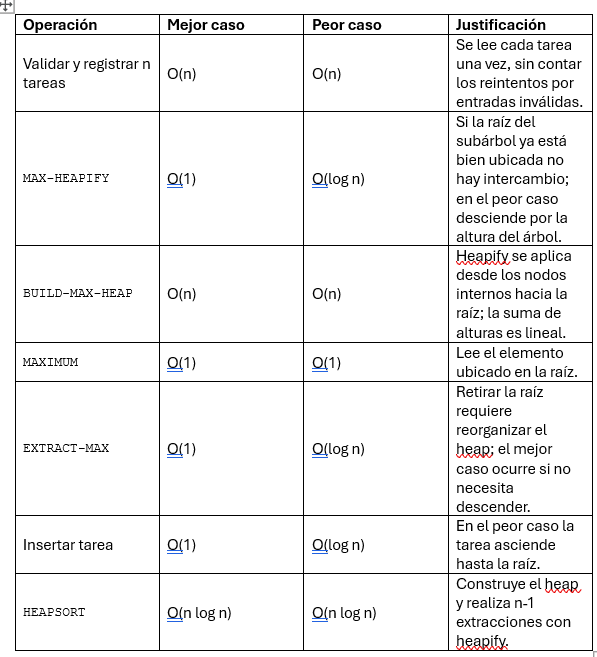

Función T[n]:

Para las operaciones de heap que recorren como máximo la altura del árbol, una cota simplificada es:

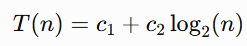

Por eso MAX-HEAPIFY, EXTRACT-MAX e inserción tienen peor caso \(O(\log n)\). Para HeapSort:

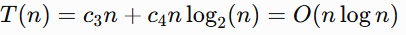

Mejor y peor caso gráfica:

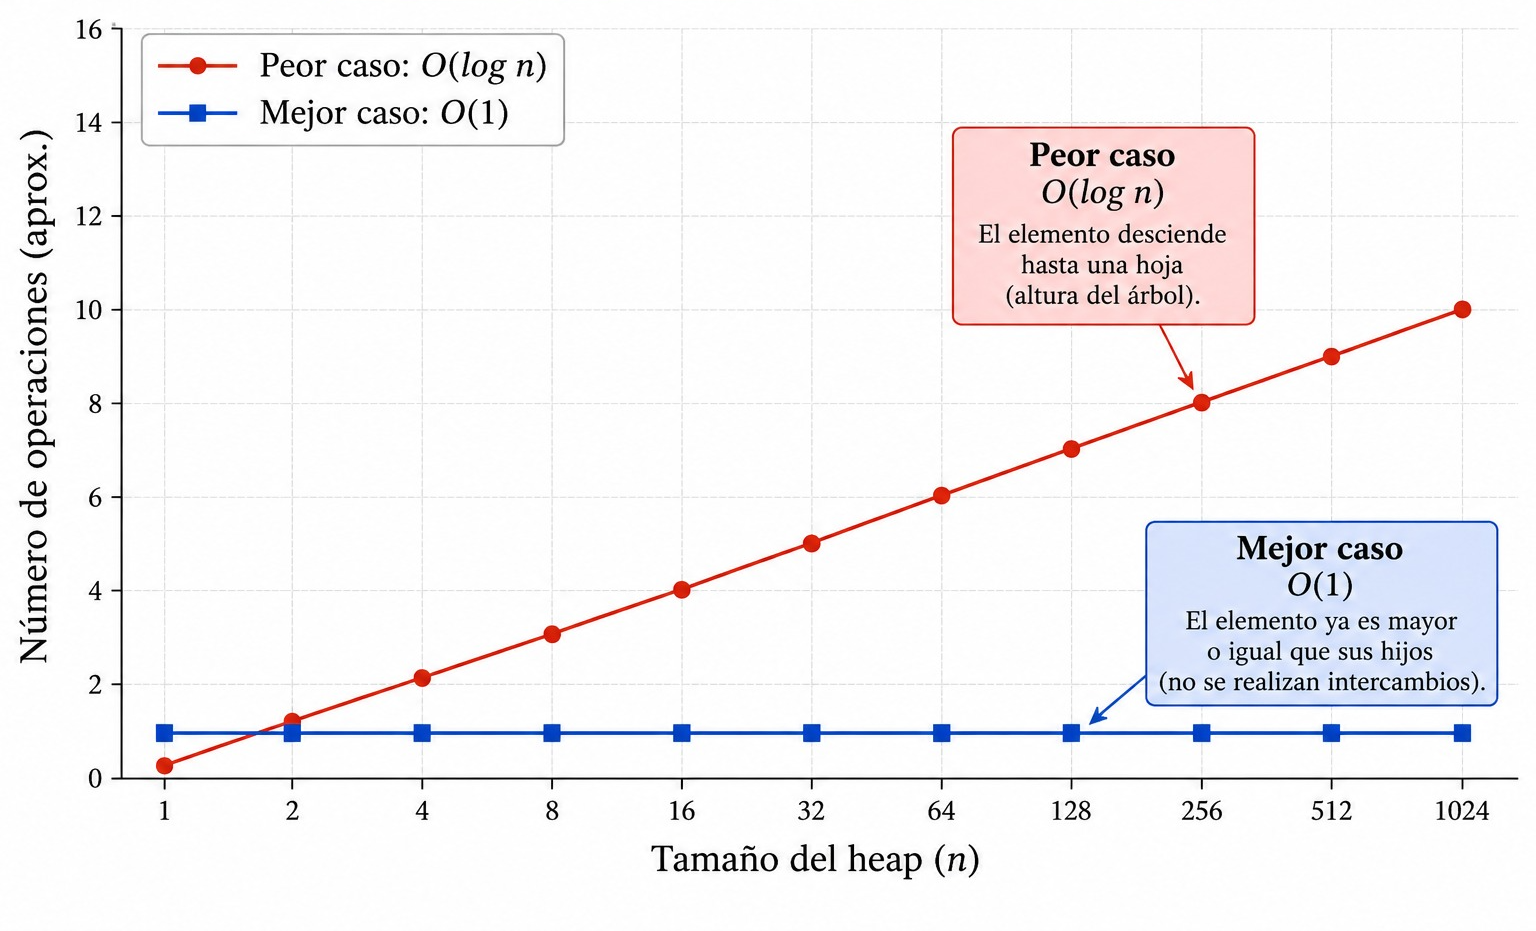

## 6) Código funcional **[15 pts]**
Incluye tu implementación completa.

No pegues código incompleto; debe ser ejecutable.


In [2]:

def es_entero(texto):
    texto = texto.strip()
    if not texto:
        return False
    if texto[0] in "+-":
        return len(texto) > 1 and texto[1:].isdigit()
    return texto.isdigit()


def solicitar_entero(mensaje, minimo=None):
    while True:
        valor = input(mensaje).strip()
        if not es_entero(valor):
            print("Error: debe ingresar un número entero. Intente nuevamente.")
            continue
        numero = int(valor)
        if minimo is not None and numero < minimo:
            print(f"Error: el valor debe ser mayor o igual que {minimo}. Intente nuevamente.")
            continue
        return numero


def solicitar_texto(mensaje):
    while True:
        valor = input(mensaje).strip()
        if valor:
            return valor
        print("Error: este campo no puede estar vacío. Intente nuevamente.")


def crear_tarea(codigo, nombre, prioridad):
    return {"codigo": codigo, "nombre": nombre, "prioridad": prioridad}


def mostrar_tarea(tarea):
    if tarea is None:
        print("No hay tareas en la cola de prioridad.")
    else:
        print(f"{tarea['codigo']} - {tarea['nombre']} | Prioridad: {tarea['prioridad']}")


def prioridades_de(tareas):
    return [tarea["prioridad"] for tarea in tareas]


def parent(i):
    return (i - 1) // 2


def left(i):
    return 2 * i + 1


def right(i):
    return 2 * i + 2


def max_heapify(heap, i, heap_size=None):
    
    if heap_size is None:
        heap_size = len(heap)

    mayor = i
    izq = left(i)
    der = right(i)

    if izq < heap_size and heap[izq]["prioridad"] > heap[mayor]["prioridad"]:
        mayor = izq
    if der < heap_size and heap[der]["prioridad"] > heap[mayor]["prioridad"]:
        mayor = der

    if mayor != i:
        heap[i], heap[mayor] = heap[mayor], heap[i]
        max_heapify(heap, mayor, heap_size)


def build_max_heap(tareas):
    
    heap = tareas.copy()
    for i in range(len(heap) // 2 - 1, -1, -1):
        max_heapify(heap, i)
    return heap


def maximum(heap):
    
    if not heap:
        return None
    return heap[0]


def extract_max(heap):
    
    if not heap:
        return None
    tarea_maxima = heap[0]
    ultimo = heap.pop()
    if heap:
        heap[0] = ultimo
        max_heapify(heap, 0)
    return tarea_maxima


def max_heap_insert(heap, tarea):
    heap.append(tarea)
    i = len(heap) - 1
    while i > 0 and heap[parent(i)]["prioridad"] < heap[i]["prioridad"]:
        heap[i], heap[parent(i)] = heap[parent(i)], heap[i]
        i = parent(i)


def heapsort(prioridades):

    arreglo = prioridades.copy()
    n = len(arreglo)

    def heapify_numeros(a, tamano, i):
        mayor = i
        izq = 2 * i + 1
        der = 2 * i + 2
        if izq < tamano and a[izq] > a[mayor]:
            mayor = izq
        if der < tamano and a[der] > a[mayor]:
            mayor = der
        if mayor != i:
            a[i], a[mayor] = a[mayor], a[i]
            heapify_numeros(a, tamano, mayor)


    for i in range(n // 2 - 1, -1, -1):
        heapify_numeros(arreglo, n, i)

    for fin in range(n - 1, 0, -1):
        arreglo[0], arreglo[fin] = arreglo[fin], arreglo[0]
        heapify_numeros(arreglo, fin, 0)

    return arreglo


def mostrar_arbol(heap):
    
    if not heap:
        print("(heap vacío)")
        return
    nivel = 0
    inicio = 0
    while inicio < len(heap):
        cantidad = 2 ** nivel
        fin = min(inicio + cantidad, len(heap))
        valores = [f"{t['prioridad']}({t['codigo']})" for t in heap[inicio:fin]]
        print(f"Nivel {nivel}: " + "   ".join(valores))
        inicio = fin
        nivel += 1


def registrar_tareas_interactivo():
    
    n = solicitar_entero("Cantidad de tareas que desea registrar (mínimo 1): ", minimo=1)
    tareas = []
    codigos = set()

    for i in range(n):
        print(f"\nRegistro de tarea {i + 1} de {n}")
        while True:
            codigo = solicitar_texto("Código: ")
            if codigo in codigos:
                print("Error: ese código ya existe. Ingrese un código diferente.")
            else:
                codigos.add(codigo)
                break
        nombre = solicitar_texto("Nombre: ")
        prioridad = solicitar_entero("Prioridad (entero): ")
        tareas.append(crear_tarea(codigo, nombre, prioridad))

    return tareas


def registrar_tarea_nueva_interactiva(heap):
    codigos = {t["codigo"] for t in heap}
    while True:
        codigo = solicitar_texto("Código de la nueva tarea: ")
        if codigo in codigos:
            print("Error: ese código ya existe en la cola. Intente nuevamente.")
        else:
            break
    nombre = solicitar_texto("Nombre de la nueva tarea: ")
    prioridad = solicitar_entero("Prioridad (entero): ")
    tarea = crear_tarea(codigo, nombre, prioridad)
    max_heap_insert(heap, tarea)
    return tarea


def ejecutar_laboratorio_interactivo():

    print("LABORATORIO: GESTIÓN DE TAREAS CON MAX-HEAP")
    tareas_originales = registrar_tareas_interactivo()
    lista_original = prioridades_de(tareas_originales)
    print("\nPUNTO 1. Registro de tareas")
    print("Lista original de prioridades:", lista_original)

    print("\nPUNTO 2. Construcción del Max-Heap")
    heap = build_max_heap(tareas_originales)
    print("Max-Heap (prioridades):", prioridades_de(heap))
    mostrar_arbol(heap)

    print("\nPUNTO 3A. Consultar tarea de mayor prioridad")
    mostrar_tarea(maximum(heap))

    print("\nPUNTO 3B. Procesar tarea de mayor prioridad")
    procesada = extract_max(heap)
    print("Tarea procesada:")
    mostrar_tarea(procesada)
    print("Nuevo Heap:", prioridades_de(heap))

    print("\nPUNTO 3C. Insertar nueva tarea")
    nueva = registrar_tarea_nueva_interactiva(heap)
    print("Tarea insertada:")
    mostrar_tarea(nueva)
    print("Heap después de insertar:", prioridades_de(heap))
    mostrar_arbol(heap)

    print("\nPUNTO 4. HeapSort de las prioridades originales")
    print("Lista original:", lista_original)
    print("Lista ordenada:", heapsort(lista_original))

    print("\nPUNTO 5. Prueba final completada.")
    print("Se registraron tareas, se construyó el Max-Heap, se consultó y extrajo el máximo,")
    print("se insertó una tarea y se ejecutó HeapSort sin sort(), sorted() ni heapq.")


def ejecutar_demostracion():
    tareas = [
        crear_tarea("T01", "Compilar proyecto", 8),
        crear_tarea("T02", "Generar backup", 4),
        crear_tarea("T03", "Renderizar video", 10),
        crear_tarea("T04", "Procesar correos", 3),
        crear_tarea("T05", "Ejecutar pruebas", 7),
    ]

    print("PUNTO 1. REGISTRAR LAS TAREAS")
    original = prioridades_de(tareas)
    print("Tareas registradas:")
    for tarea in tareas:
        mostrar_tarea(tarea)
    print("Lista original de prioridades:", original)

    print("\nPUNTO 2. CONSTRUIR EL MAX-HEAP")
    heap = build_max_heap(tareas)
    print("Max-Heap (prioridades):", prioridades_de(heap))
    print("Representación del árbol:")
    mostrar_arbol(heap)

    print("\nPUNTO 3A. CONSULTAR LA TAREA DE MAYOR PRIORIDAD")
    print("Tarea de mayor prioridad:")
    mostrar_tarea(maximum(heap))
    print("El heap no cambia después de consultar:", prioridades_de(heap))

    print("\nPUNTO 3B. PROCESAR LA TAREA DE MAYOR PRIORIDAD")
    procesada = extract_max(heap)
    print("Tarea procesada:")
    mostrar_tarea(procesada)
    print("Nuevo Heap:", prioridades_de(heap))

    print("\nPUNTO 3C. INSERTAR UNA NUEVA TAREA")
    nueva = crear_tarea("T06", "Actualizar servidor", 12)
    max_heap_insert(heap, nueva)
    print("Tarea insertada:")
    mostrar_tarea(nueva)
    print("Heap después de insertar:", prioridades_de(heap))
    print("Árbol después de insertar:")
    mostrar_arbol(heap)

    print("\nPUNTO 4. HEAPSORT")
    print("Lista original de prioridades:", original)
    print("Lista ordenada ascendentemente:", heapsort(original))

    print("\nPUNTO 5. PRUEBA FINAL")
    print("Se probaron cinco tareas iniciales y una sexta tarea insertada.")
    print("La implementación usa arreglos y algoritmos manuales; no usa heapq, sort() ni sorted().")

#ejecutar_demostracion()

ejecutar_laboratorio_interactivo()



LABORATORIO: GESTIÓN DE TAREAS CON MAX-HEAP

Registro de tarea 1 de 3

Registro de tarea 2 de 3

Registro de tarea 3 de 3

PUNTO 1. Registro de tareas
Lista original de prioridades: [5, 8, 9]

PUNTO 2. Construcción del Max-Heap
Max-Heap (prioridades): [9, 8, 5]
Nivel 0: 9(1014)
Nivel 1: 8(1013)   5(1012)

PUNTO 3A. Consultar tarea de mayor prioridad
1014 - correccion proyecto | Prioridad: 9

PUNTO 3B. Procesar tarea de mayor prioridad
Tarea procesada:
1014 - correccion proyecto | Prioridad: 9
Nuevo Heap: [8, 5]

PUNTO 3C. Insertar nueva tarea
Tarea insertada:
1010 - eliminar proyecto sin correccion | Prioridad: 12
Heap después de insertar: [12, 5, 8]
Nivel 0: 12(1010)
Nivel 1: 5(1012)   8(1013)

PUNTO 4. HeapSort de las prioridades originales
Lista original: [5, 8, 9]
Lista ordenada: [5, 8, 9]

PUNTO 5. Prueba final completada.
Se registraron tareas, se construyó el Max-Heap, se consultó y extrajo el máximo,
se insertó una tarea y se ejecutó HeapSort sin sort(), sorted() ni heapq.


## 7) Tests aplicados **[15 pts]**

In [4]:

def es_max_heap(heap):
    for i in range(len(heap)):
        izq, der = left(i), right(i)
        if izq < len(heap) and heap[i]["prioridad"] < heap[izq]["prioridad"]:
            return False
        if der < len(heap) and heap[i]["prioridad"] < heap[der]["prioridad"]:
            return False
    return True

datos = [
    crear_tarea("A", "Tarea A", 8),
    crear_tarea("B", "Tarea B", 4),
    crear_tarea("C", "Tarea C", 10),
    crear_tarea("D", "Tarea D", 3),
    crear_tarea("E", "Tarea E", 7),
]
h = build_max_heap(datos)
assert es_max_heap(h)
assert maximum(h)["prioridad"] == 10
assert len(h) == 5


tamano_antes = len(h)
maximum(h)
assert len(h) == tamano_antes


extraida = extract_max(h)
assert extraida["prioridad"] == 10
assert len(h) == 4
assert es_max_heap(h)

max_heap_insert(h, crear_tarea("F", "Tarea F", 12))
assert maximum(h)["prioridad"] == 12
assert es_max_heap(h)
assert len(h) == 5


entrada = [8, 4, 10, 3, 7]
copia_antes = entrada.copy()
assert heapsort(entrada) == [3, 4, 7, 8, 10]
assert entrada == copia_antes

assert heapsort([]) == []
assert heapsort([5]) == [5]
assert heapsort([4, 4, 1, 4]) == [1, 4, 4, 4]
assert extract_max([]) is None
assert maximum([]) is None

print("Todas las pruebas finalizaron correctamente.")
print("Max-Heap validado:", prioridades_de(h))
print("HeapSort de [8, 4, 10, 3, 7]:", heapsort([8, 4, 10, 3, 7]))
print("Casos límite probados: lista vacía, un elemento y prioridades repetidas.")



Todas las pruebas finalizaron correctamente.
Max-Heap validado: [12, 8, 4, 3, 7]
HeapSort de [8, 4, 10, 3, 7]: [3, 4, 7, 8, 10]
Casos límite probados: lista vacía, un elemento y prioridades repetidas.
